# Explainable AI

In [1]:
%load_ext autoreload
%autoreload 2

Explanation family:
- Feature importance: what are the important features?
- Rule: how does the model predict?
- Counterfactuals: what should I do to change the model?
- Relevant instances: what instances steered the learning process?

In [2]:
from sklearn.metrics import classification_report
import pandas
from transformations import center_and_scale, drop_boolean
import pickle

In [3]:
train_path = '../dataset/train.csv'
test_path = '../dataset/test.csv'

train_dataset = pandas.read_csv(train_path, skipinitialspace=True)
test_dataset = pandas.read_csv(test_path, skipinitialspace=True)

In [4]:
train_dataset['is_tarmac'] = train_dataset['is_tarmac'].astype(int)
test_dataset['is_tarmac'] = test_dataset['is_tarmac'].astype(int)

In [5]:
decision_tree_path = './logs/best_decision_tree.pkl'
knn_path = './logs/best_knn.pkl'
neural_network_path = './logs/best_neural_network.pth'
bagging_path = './logs/best_bagging.pkl'
svc_path = './logs/best_svc.pkl'

In [6]:
train_labels = train_dataset["label"]
test_labels = test_dataset["label"]

train_data = train_dataset.drop("label", axis="columns", inplace=False)
test_data = test_dataset.drop("label", axis="columns", inplace=False)


full_dataset = pandas.concat((train_data, test_data))

with open(bagging_path, 'rb') as file:
    model = pickle.load(file)

train_labels_model = model.predict(train_data)
test_labels_model = model.predict(test_data)
print("Prediction:", test_labels_model)

validation = classification_report(test_labels, test_labels_model, output_dict=True)

Prediction: [1 0 1 ... 0 0 0]


In [7]:
for key in validation.keys():
    print(key, " ", validation[key])

0   {'precision': 0.9175289105295191, 'recall': 0.7664734594264796, 'f1-score': 0.8352263283284392, 'support': 19668.0}
1   {'precision': 0.3146821844225604, 'recall': 0.6088337182448037, 'f1-score': 0.41491245327562465, 'support': 3464.0}
accuracy   0.7428670240359675
macro avg   {'precision': 0.6161055474760397, 'recall': 0.6876535888356416, 'f1-score': 0.6250693908020319, 'support': 23132.0}
weighted avg   {'precision': 0.8272530563347023, 'recall': 0.7428670240359675, 'f1-score': 0.7722846344332746, 'support': 23132.0}


In [8]:
perturbation_data = train_data
perturbation_labels = train_labels
perturbation_predictions = train_labels_model

explanation_data = test_data
explanation_labels = test_labels
explanation_predictions = test_labels_model

explanations = dict()

# Feature importance

## Shap

[Reference](https://shap.readthedocs.io/en/latest/index.html)

Shap performs a set of feature importance tests by removing features, and analyzing the impact on the model predictions.
For a feature $i$ in a set of features $M$, and a model $f$ its Shapley value is defined as

$$
\phi_i(f) =
\sum_{M' \subseteq M \setminus \{i\}}
\underbrace{\binom{\mid M \mid - 1}{\mid M'\mid}^{-1}}_{weight \text{ } all \text{ } possible \text{ } permutations \text{ } adding \text{ } up \text{ } to \text{ } M' \cup \{i\}}
(\overbrace{f(M' \cup \{i\})}^{model \text{ } with \text{ } the \text{ } feature} - \underbrace{f(M')}_{model \text{ } without \text{ } the \text{ } feature})
$$

Permutations (the binomial coefficient) are exponential, thus SHAP leverages a Markov chain-Monte Carlo approximation.

Since features can't really be added to/removed from a model (the $f(M' \cup \{i\})$), SHAP conditions the model on a "null" value of the feature of interest, miming the absence of features.
Note that in different models, this may be different, e.g.,
- In a decision tree, this would mean removing nodes from the tree
- In a neural network, this would mean assign to trim a subnetwork or assign a "null" value to some activations

Thus, SHAP provides different implementations according to which model we are trying to explain.

### Conditioning

Conditioning often relies on estimating conditioned values, which are usually learned from data.
- Interventional: A casual model is learned from data, and perturbations follow said model
- Statistical: Distributions are learned from data

Reference: [TreeExplainer](https://shap.readthedocs.io/en/stable/generated/shap.TreeExplainer.html)

### Explaining Trees (or several Trees)

In [10]:
import shap


interventional_explanation_algorithm = shap.TreeExplainer(
    model=model.estimators_[0],
    data=train_data.sample(500),                       # perturb on a causal model induced on perturbation data
    feature_perturbation="interventional",  # use a causal model
)

distributional_explanation_algorithm = shap.TreeExplainer(
    model=model.estimators_[0],
    feature_perturbation="tree_path_dependent"  # condition on the distribution learned on the train data
)

/opt/homebrew/anaconda3/envs/xai/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [11]:
interventional_explanations = interventional_explanation_algorithm(explanation_data,  check_additivity=False)
distributional_explanations = distributional_explanation_algorithm(explanation_data)

explanations["shap_interventional"] = interventional_explanations.values
explanations["shap_distributional"] = distributional_explanations.values

 97%|=================== | 44910/46264 [00:27<00:00]       

Beeswarm plot for label 1


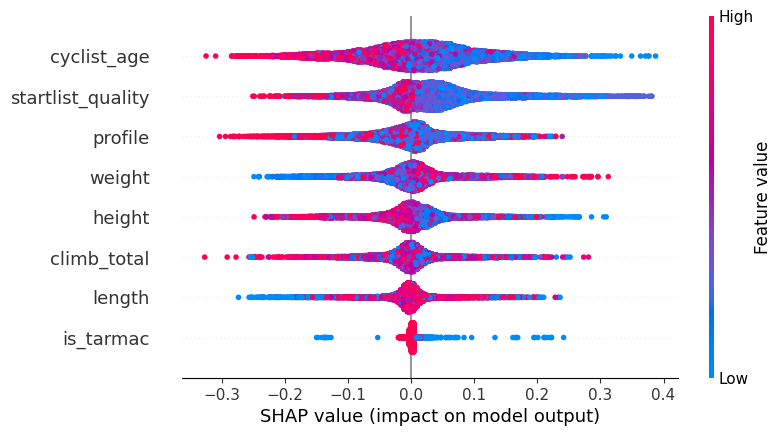

None

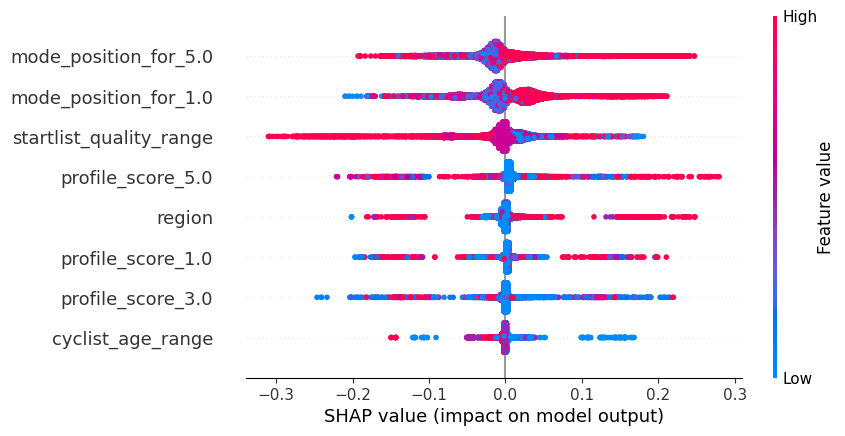

None

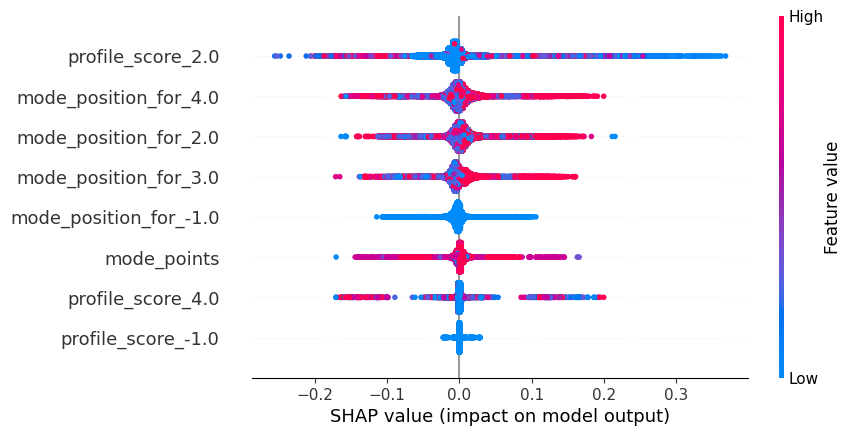

None

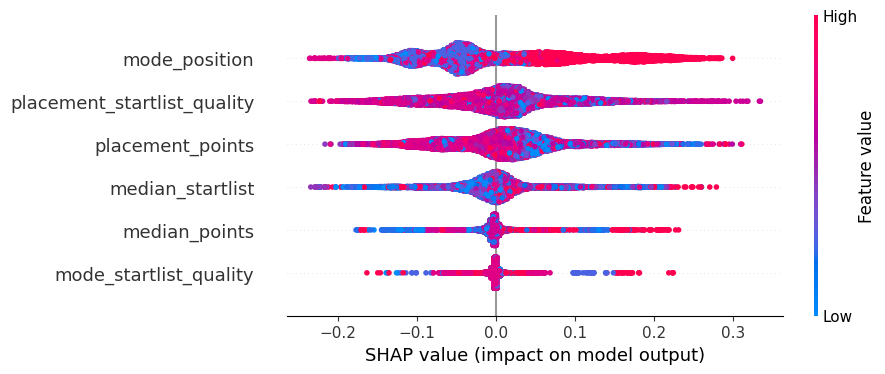

None

Beeswarm plot for label 0


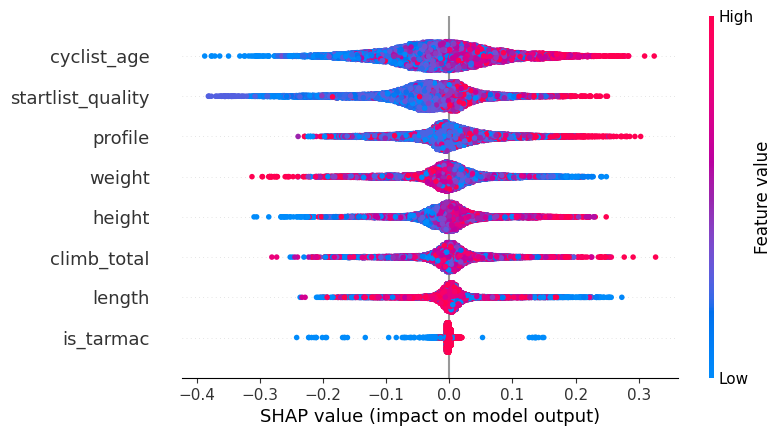

None

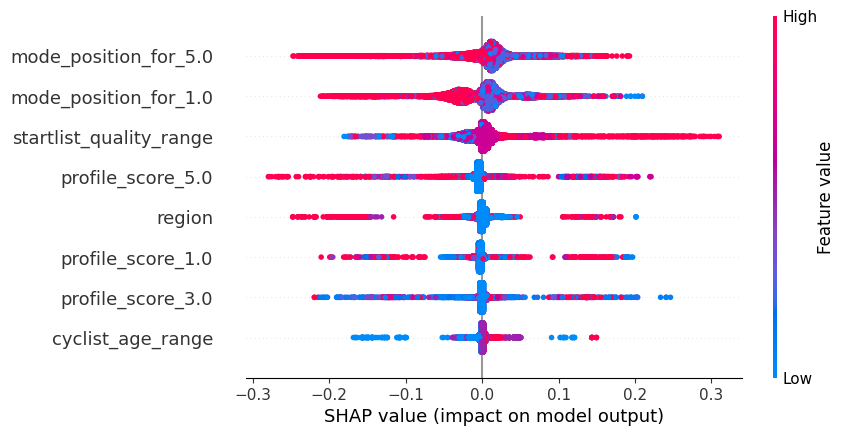

None

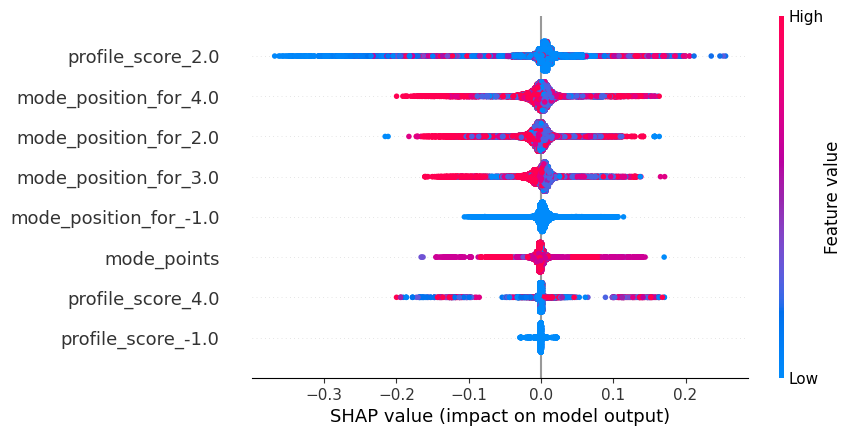

None

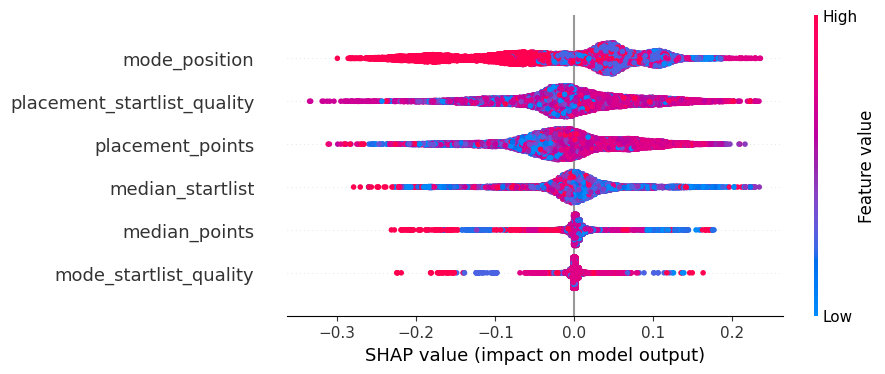

None

In [15]:
from IPython.display import display

labels = [1, 0]
features_intervals = [
    (0, 8),
    (8, 16),
    (16, 24),
    (24, len(test_data.columns)),
]

for label in labels:
    print(f"Beeswarm plot for label {label}")
    for feature_interval in features_intervals:
        start, end = feature_interval
        display(shap.plots.beeswarm(interventional_explanations[:,start: end, label]))

Beeswarm plot for label 1


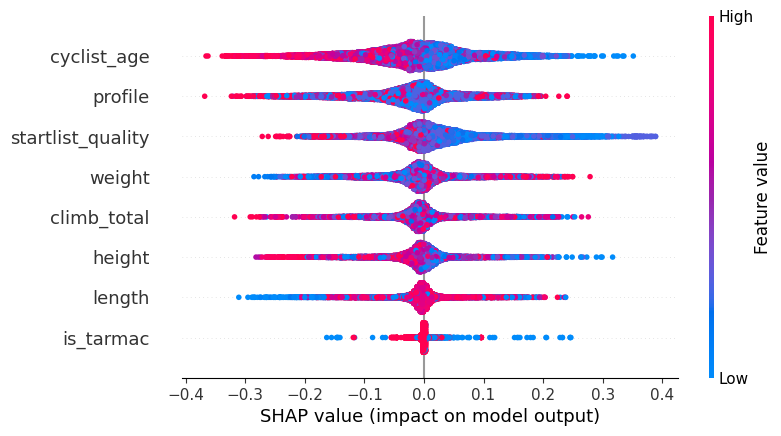

None

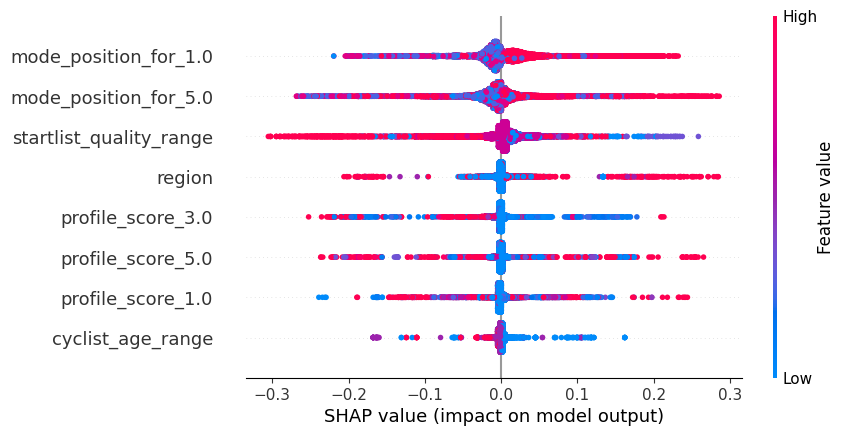

None

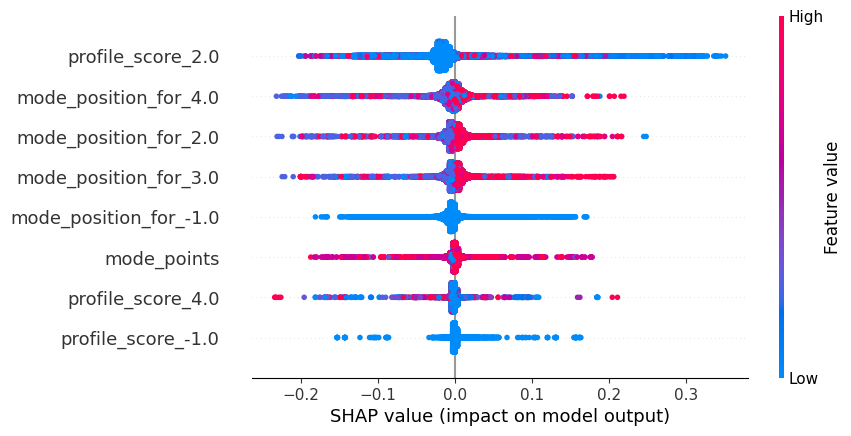

None

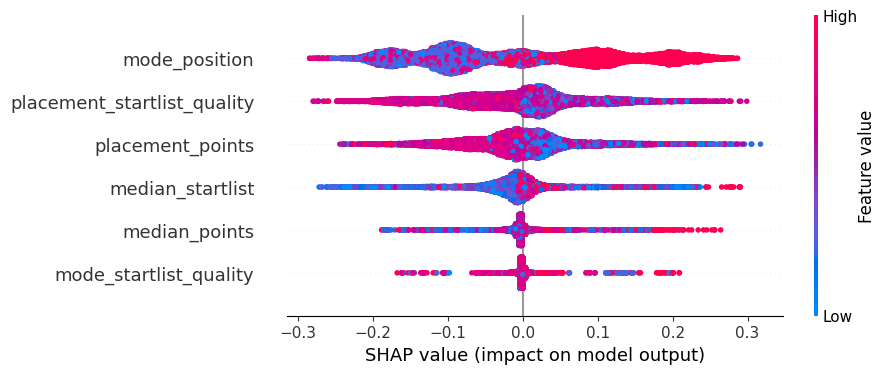

None

Beeswarm plot for label 0


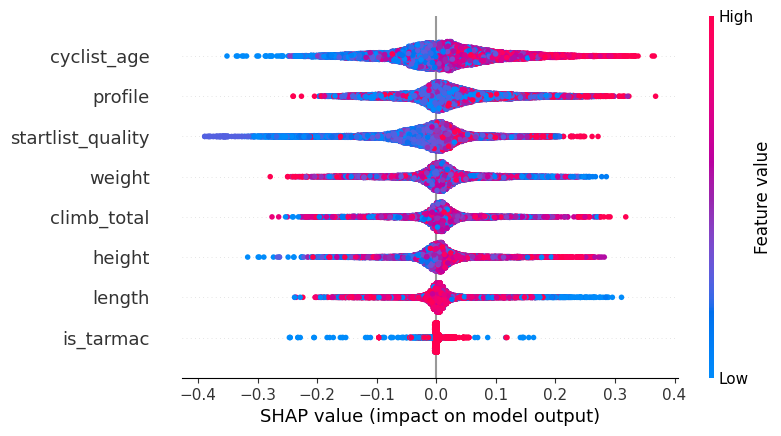

None

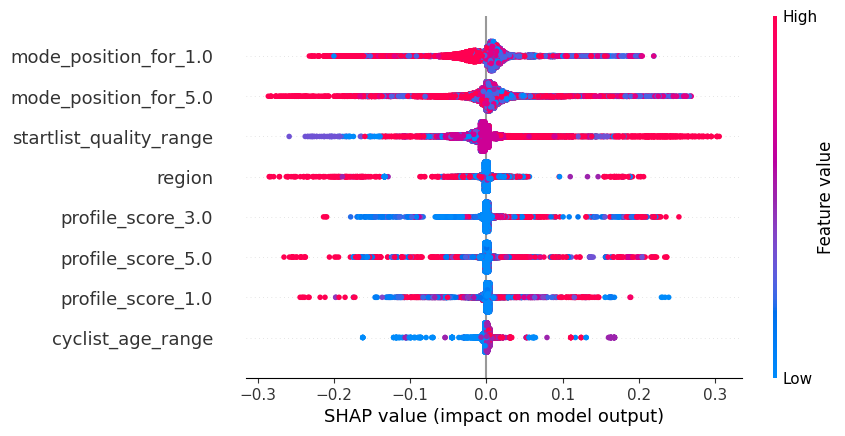

None

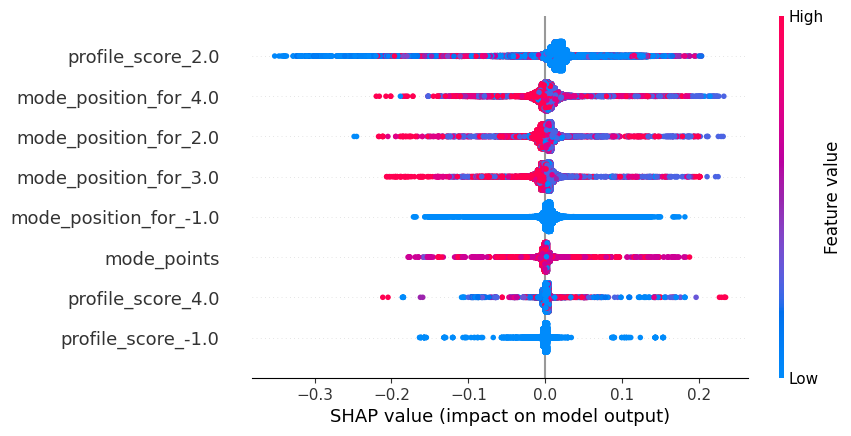

None

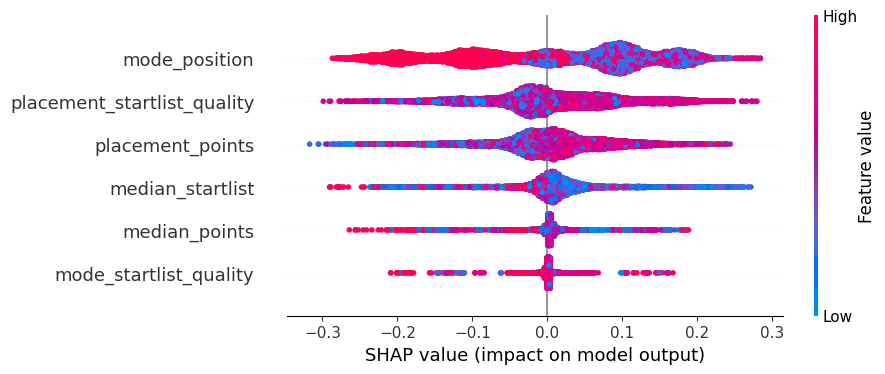

None

In [16]:
for label in labels:
    print(f"Beeswarm plot for label {label}")
    for feature_interval in features_intervals:
        start, end = feature_interval
        display(shap.plots.beeswarm(distributional_explanations[:,start: end, label]))

**Observation.** Purely distributional and causal perturbation may impact the scores of perturbation-based algorithms.

Below, a quick analysis.

---

### Perturbation differences in Shap

In [18]:
import seaborn

explanation_differences = interventional_explanations.values - distributional_explanations.values

scaling_value = max((abs(interventional_explanations.values).max(), abs(distributional_explanations.values).max()))
maximum_differences_per_instance = explanation_differences.max(axis=1)
maximum_differences_per_feature = explanation_differences.max(axis=0)

<Axes: ylabel='Density'>

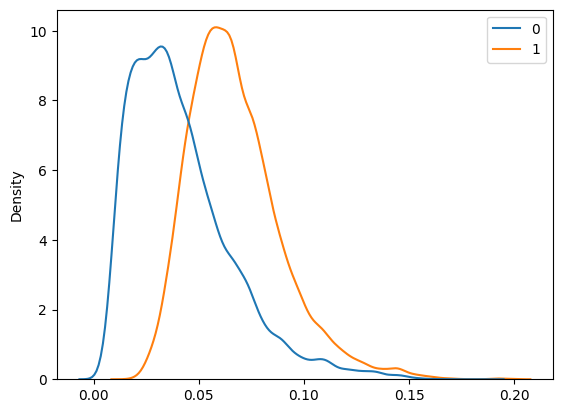

In [19]:
seaborn.kdeplot(maximum_differences_per_instance)

**Observation.** Most instances have a moderate-to-high explanation difference.

['length', 'climb_total', 'profile', 'startlist_quality', 'cyclist_age', 'is_tarmac', 'weight', 'height', 'cyclist_age_range', 'region', 'startlist_quality_range', 'profile_score_5.0', 'mode_position_for_5.0', 'profile_score_1.0', 'mode_position_for_1.0', 'profile_score_3.0', 'mode_position_for_3.0', 'profile_score_2.0', 'mode_position_for_2.0', 'profile_score_-1.0', 'mode_position_for_-1.0', 'profile_score_4.0', 'mode_position_for_4.0', 'mode_points', 'mode_position', 'mode_startlist_quality', 'median_points', 'median_startlist', 'placement_points', 'placement_startlist_quality']


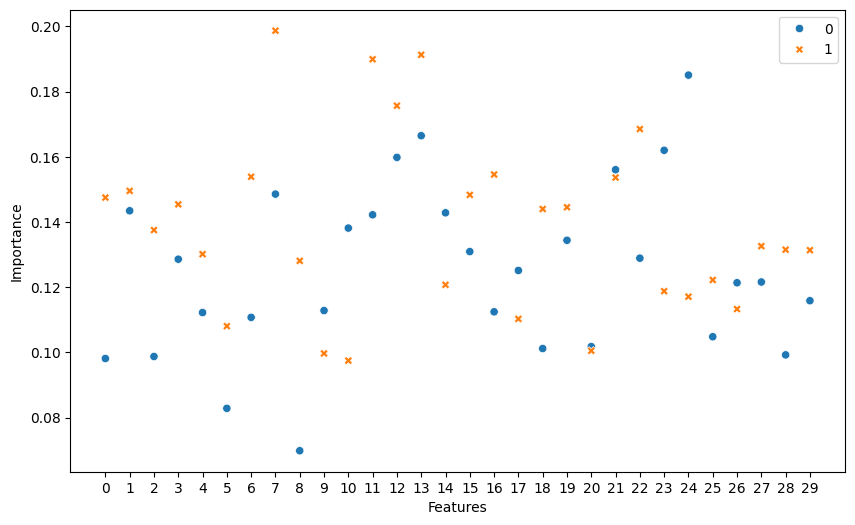

0 length
1 climb_total
2 profile
3 startlist_quality
4 cyclist_age
5 is_tarmac
6 weight
7 height
8 cyclist_age_range
9 region
10 startlist_quality_range
11 profile_score_5.0
12 mode_position_for_5.0
13 profile_score_1.0
14 mode_position_for_1.0
15 profile_score_3.0
16 mode_position_for_3.0
17 profile_score_2.0
18 mode_position_for_2.0
19 profile_score_-1.0
20 mode_position_for_-1.0
21 profile_score_4.0
22 mode_position_for_4.0
23 mode_points
24 mode_position
25 mode_startlist_quality
26 median_points
27 median_startlist
28 placement_points
29 placement_startlist_quality
83988
90961
38786
31138
60578


In [22]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

seaborn.scatterplot(maximum_differences_per_feature)
print(train_data.columns.tolist())
plt.xlabel('Features')  # Label for x-axis
plt.ylabel('Importance')  # Label for y-axis

# Set custom x-axis ticks
plt.xticks(ticks=[i for i in range(len(train_data.columns.tolist()))])

plt.show()

for i in range(len(train_data.columns.tolist())):
    print(i, train_data.columns[i])

print(len(train_data[train_data['profile'] == 1]))
print(len(train_data[train_data['profile'] == 2]))
print(len(train_data[train_data['profile'] == 3]))
print(len(train_data[train_data['profile'] == 4]))
print(len(train_data[train_data['profile'] == 5]))

# 7, 11, 12, 13

**Observation.** profile_score_5.0, mode_position, profile_score_1.0 and height are highly impacted by the use of causal/distributional perturbations.

## Explanation analysis

Are some features generally more impactful?

In [118]:
pandas.set_option('display.max_columns', None)
pandas.set_option('display.width', 1000)

interventional_explanations_df_1 = pandas.DataFrame(interventional_explanations.values[:,:, 1], columns=train_data.columns.tolist())
interventional_explanations_df_0 = pandas.DataFrame(interventional_explanations.values[:,:, 0], columns=train_data.columns.tolist())
display(interventional_explanations_df_1.describe().drop("count", axis="rows"))
display(interventional_explanations_df_0.describe().drop("count", axis="rows"))

,length,climb_total,profile,startlist_quality,cyclist_age,is_tarmac,weight,height,cyclist_age_range,region,startlist_quality_range,profile_score_5.0,mode_position_for_5.0,profile_score_1.0,mode_position_for_1.0,profile_score_3.0,mode_position_for_3.0,profile_score_2.0,mode_position_for_2.0,profile_score_-1.0,mode_position_for_-1.0,profile_score_4.0,mode_position_for_4.0,mode_points,mode_position,mode_startlist_quality,median_points,median_startlist,placement_points,placement_startlist_quality
mean,-0.003533,-0.001848,-0.002725,0.030372,0.011599,0.001345,0.002754,0.001922,-0.000198,0.000900,-0.006681,0.004134,-0.003961,0.002880,0.003526,0.000252,0.000692,0.000376,0.004531,0.000281,-0.003994,-0.000146,0.000860,0.001095,0.009863,-0.000133,-0.002554,-0.001897,0.009450,0.003454
std,0.037178,0.046456,0.064171,0.072300,0.084051,0.006998,0.057526,0.051831,0.011012,0.018309,0.040390,0.023576,0.052231,0.016259,0.043970,0.018388,0.025937,0.052582,0.029755,0.001940,0.017999,0.018018,0.033079,0.015870,0.096601,0.012209,0.020884,0.048163,0.065418,0.071260
min,-0.273152,-0.326649,-0.303023,-0.250456,-0.324455,-0.149630,-0.248705,-0.248435,-0.149711,-0.201350,-0.310172,-0.221017,-0.192834,-0.196938,-0.209795,-0.246439,-0.171080,-0.255384,-0.163638,-0.022383,-0.114169,-0.170667,-0.163552,-0.170398,-0.235437,-0.162887,-0.176650,-0.233934,-0.215905,-0.233626
25%,-0.012495,-0.018778,-0.032384,-0.011010,-0.038335,0.000742,-0.021506,-0.017492,-0.001484,-0.002512,-0.010645,0.002511,-0.021447,0.001283,-0.015035,-0.001031,-0.007464,-0.011728,-0.004300,-0.000159,-0.006206,-0.000614,-0.007986,-0.001514,-0.057454,-0.002129,-0.006117,-0.019297,-0.026850,-0.036929
50%,-0.002485,-0.001919,0.000551,0.024426,0.012752,0.001337,0.001517,0.002317,-0.000226,-0.000027,-0.001932,0.004254,-0.010824,0.002082,-0.003480,0.000072,-0.002141,-0.005729,0.002013,0.000112,-0.002486,0.000098,-0.000629,0.000924,-0.019718,-0.000327,-0.002340,-0.001619,0.012306,0.006379
75%,0.007598,0.013760,0.025335,0.060591,0.062513,0.001905,0.023293,0.024604,0.000467,0.001968,0.011239,0.005988,0.008265,0.003127,0.026212,0.000813,0.007268,0.001105,0.009272,0.000443,0.000181,0.000768,0.007850,0.003264,0.073105,0.001232,0.000648,0.013869,0.044122,0.037976
max,0.236265,0.281062,0.239476,0.381591,0.387400,0.241768,0.312511,0.309230,0.168528,0.247930,0.180694,0.279798,0.247566,0.210624,0.211608,0.219826,0.160677,0.368338,0.215483,0.029118,0.105938,0.199816,0.199736,0.165776,0.299870,0.224847,0.231553,0.279322,0.311489,0.335057


,length,climb_total,profile,startlist_quality,cyclist_age,is_tarmac,weight,height,cyclist_age_range,region,startlist_quality_range,profile_score_5.0,mode_position_for_5.0,profile_score_1.0,mode_position_for_1.0,profile_score_3.0,mode_position_for_3.0,profile_score_2.0,mode_position_for_2.0,profile_score_-1.0,mode_position_for_-1.0,profile_score_4.0,mode_position_for_4.0,mode_points,mode_position,mode_startlist_quality,median_points,median_startlist,placement_points,placement_startlist_quality
mean,0.003533,0.001848,0.002725,-0.030372,-0.011599,-0.001345,-0.002754,-0.001922,0.000198,-0.000900,0.006681,-0.004134,0.003961,-0.002880,-0.003526,-0.000252,-0.000692,-0.000376,-0.004531,-0.000281,0.003994,0.000146,-0.000860,-0.001095,-0.009863,0.000133,0.002554,0.001897,-0.009450,-0.003454
std,0.037178,0.046456,0.064171,0.072300,0.084051,0.006998,0.057526,0.051831,0.011012,0.018309,0.040390,0.023576,0.052231,0.016259,0.043970,0.018388,0.025937,0.052582,0.029755,0.001940,0.017999,0.018018,0.033079,0.015870,0.096601,0.012209,0.020884,0.048163,0.065418,0.071260
min,-0.236265,-0.281062,-0.239476,-0.381591,-0.387400,-0.241768,-0.312511,-0.309230,-0.168528,-0.247930,-0.180694,-0.279798,-0.247566,-0.210624,-0.211608,-0.219826,-0.160677,-0.368338,-0.215483,-0.029118,-0.105938,-0.199816,-0.199736,-0.165776,-0.299870,-0.224847,-0.231553,-0.279322,-0.311489,-0.335057
25%,-0.007598,-0.013760,-0.025335,-0.060591,-0.062513,-0.001905,-0.023293,-0.024604,-0.000467,-0.001968,-0.011239,-0.005988,-0.008265,-0.003127,-0.026212,-0.000813,-0.007268,-0.001105,-0.009272,-0.000443,-0.000181,-0.000768,-0.007850,-0.003264,-0.073105,-0.001232,-0.000648,-0.013869,-0.044122,-0.037976
50%,0.002485,0.001919,-0.000551,-0.024426,-0.012752,-0.001337,-0.001517,-0.002317,0.000226,0.000027,0.001932,-0.004254,0.010824,-0.002082,0.003480,-0.000072,0.002141,0.005729,-0.002013,-0.000112,0.002486,-0.000098,0.000629,-0.000924,0.019718,0.000327,0.002340,0.001619,-0.012306,-0.006379
75%,0.012495,0.018778,0.032384,0.011010,0.038335,-0.000742,0.021506,0.017492,0.001484,0.002512,0.010645,-0.002511,0.021447,-0.001283,0.015035,0.001031,0.007464,0.011728,0.004300,0.000159,0.006206,0.000614,0.007986,0.001514,0.057454,0.002129,0.006117,0.019297,0.026850,0.036929
max,0.273152,0.326649,0.303023,0.250456,0.324455,0.149630,0.248705,0.248435,0.149711,0.201350,0.310172,0.221017,0.192834,0.196938,0.209795,0.246439,0.171080,0.255384,0.163638,0.022383,0.114169,0.170667,0.163552,0.170398,0.235437,0.162887,0.176650,0.233934,0.215905,0.233626


#### For what instances are some features more/less impactful?

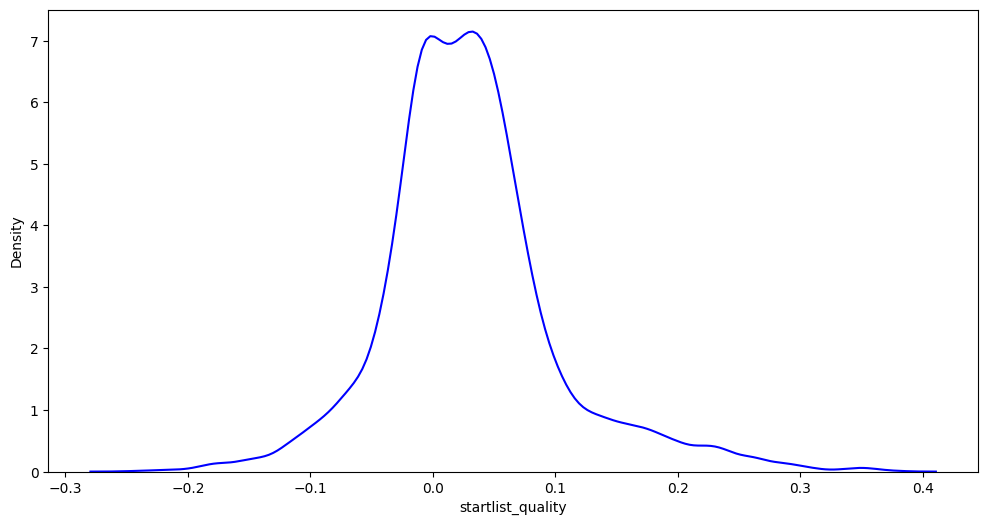

In [119]:
import matplotlib.pyplot as plt
feature_of_interest = "startlist_quality"
plt.figure(figsize=(12, 6))
seaborn.kdeplot(interventional_explanations_df_1, x=feature_of_interest, color='blue')
plt.show()

In [120]:
number_quantiles = 40
quantiles = interventional_explanations_df_1["cyclist_age"].quantile([q / number_quantiles for q in (range(number_quantiles))])
quantiles.diff()  # pick differences in quantiles

0.000         NaN
0.025    0.159025
0.050    0.027533
0.075    0.025240
0.100    0.017927
0.125    0.012749
0.150    0.011492
0.175    0.010432
0.200    0.007962
0.225    0.007338
0.250    0.006421
0.275    0.006174
0.300    0.005483
0.325    0.005685
0.350    0.005189
0.375    0.004955
0.400    0.004519
0.425    0.004920
0.450    0.004545
0.475    0.004707
0.500    0.004911
0.525    0.004878
0.550    0.004774
0.575    0.004536
0.600    0.004789
0.625    0.004967
0.650    0.004673
0.675    0.005126
0.700    0.005589
0.725    0.004975
0.750    0.005454
0.775    0.006387
0.800    0.006884
0.825    0.007496
0.850    0.009273
0.875    0.011931
0.900    0.012960
0.925    0.015175
0.950    0.019140
0.975    0.027718
Name: cyclist_age, dtype: float64

In [122]:
import numpy

quantile_of_interest = quantiles[0.1]
interested_explanations = interventional_explanations_df_1[feature_of_interest].values

highly_impacted_instances = numpy.argwhere(interested_explanations <= quantile_of_interest).squeeze()
moderately_impacted_instances = numpy.array([i for i in range(interventional_explanations.shape[0]) if i not in highly_impacted_instances])

### What are the differences in instances for which the selected features is highly important?

In [123]:
full_dataset.iloc[highly_impacted_instances].describe().drop("count", axis="rows") - full_dataset.iloc[moderately_impacted_instances].describe().drop("count", axis="rows")

,length,climb_total,profile,startlist_quality,cyclist_age,is_tarmac,weight,height,cyclist_age_range,region,startlist_quality_range,profile_score_5.0,mode_position_for_5.0,profile_score_1.0,mode_position_for_1.0,profile_score_3.0,mode_position_for_3.0,profile_score_2.0,mode_position_for_2.0,profile_score_-1.0,mode_position_for_-1.0,profile_score_4.0,mode_position_for_4.0,mode_points,mode_position,mode_startlist_quality,median_points,median_startlist,placement_points,placement_startlist_quality
mean,0.110611,0.227056,-0.016875,0.016632,0.024009,0.018093,-0.068413,-0.060726,0.018347,0.013877,0.03735,-0.046346,0.033801,-0.118852,0.058533,-0.044583,0.034386,-0.064699,0.068981,-0.132787,0.068924,-0.001465,0.028832,0.023449,0.069537,0.039242,-0.015992,0.010904,2.257738,1.710833
std,-0.087868,0.044927,0.129170,0.005900,0.007622,-0.030751,0.024768,-0.004091,-0.004293,0.025643,-0.00199,-0.117081,0.000742,-0.215091,-0.012027,-0.039596,0.001546,-0.088039,0.017125,-0.200132,0.021150,-0.032748,-0.002149,-0.027793,0.001200,-0.009006,-0.050626,-0.024531,-183.831284,32.825675
min,0.000000,0.000000,0.000000,0.018590,1.000000,0.000000,0.532389,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.154012,0.462104,16304.758331,957.628891
25%,0.310482,1.021000,0.000000,0.000000,0.000000,0.000000,-0.177463,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.023902,0.098303,0.034965
50%,-0.005433,0.430500,0.000000,-0.010623,-1.000000,0.000000,0.000000,-0.063754,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.010503,-0.009591
75%,-0.023286,0.578500,0.000000,0.005312,0.000000,0.000000,0.000000,-0.175736,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.069050,-0.002469,0.000000
max,0.000000,0.000000,0.000000,0.000000,-2.000000,0.000000,-1.597167,-1.230155,0.000000,0.000000,0.00000,-18.000000,0.000000,-7.000000,0.000000,-3.000000,0.000000,-6.000000,0.000000,-13.000000,0.000000,-4.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-1535.970589,0.000000


<Axes: xlabel='startlist_quality', ylabel='Density'>

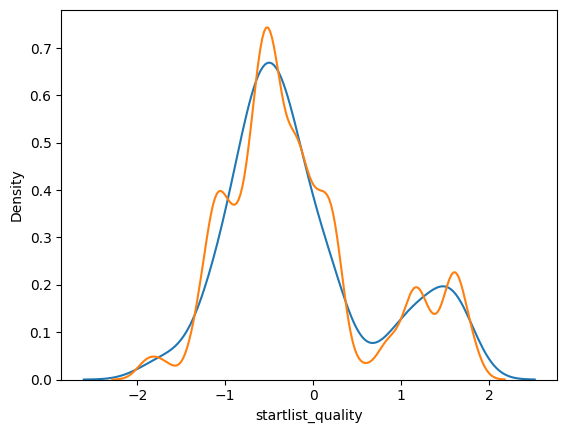

In [124]:
seaborn.kdeplot(full_dataset.iloc[highly_impacted_instances], x="startlist_quality")
seaborn.kdeplot(full_dataset.iloc[moderately_impacted_instances], x="startlist_quality")

<Axes: xlabel='mode_position', ylabel='Density'>

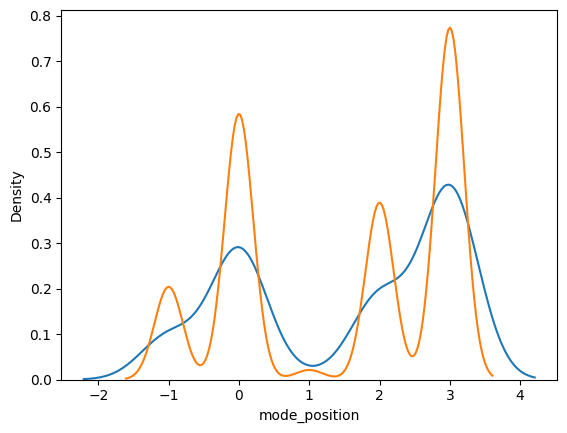

In [125]:
seaborn.kdeplot(full_dataset.iloc[highly_impacted_instances], x="mode_position")
seaborn.kdeplot(full_dataset.iloc[moderately_impacted_instances], x="mode_position")

---

## Validation

- Sensitivity to perturbation: does perturbation in the important features actually impact the model?
- Iterative removal: does removing important features worsen the model?
- Iterative addition: does adding important features improves the model?

We are starting from

In [67]:
pandas.DataFrame(validation)

,0,1,accuracy,macro avg,weighted avg
precision,0.917529,0.314682,0.742867,0.616106,0.827253
recall,0.766473,0.608834,0.742867,0.687654,0.742867
f1-score,0.835226,0.414912,0.742867,0.625069,0.772285
support,19668.000000,3464.000000,0.742867,23132.000000,23132.000000


### What features to work on? The most important ones!

In [130]:
mean_absolute_importances = interventional_explanations_df_1.abs().mean()
features_by_importance = interventional_explanations_df_1.columns[mean_absolute_importances.argsort()].tolist()
features_by_importance

['profile_score_-1.0',
 'is_tarmac',
 'cyclist_age_range',
 'mode_startlist_quality',
 'profile_score_4.0',
 'profile_score_3.0',
 'profile_score_1.0',
 'region',
 'mode_points',
 'mode_position_for_-1.0',
 'median_points',
 'profile_score_5.0',
 'mode_position_for_3.0',
 'mode_position_for_2.0',
 'mode_position_for_4.0',
 'length',
 'startlist_quality_range',
 'profile_score_2.0',
 'climb_total',
 'mode_position_for_1.0',
 'median_startlist',
 'mode_position_for_5.0',
 'height',
 'weight',
 'profile',
 'placement_points',
 'placement_startlist_quality',
 'startlist_quality',
 'cyclist_age',
 'mode_position']

We start by constructing a set of corrupted datasets where noise at different magnitudes is inserted into the original dataset...

In [131]:
random_noise = numpy.random.rand(test_data.shape[0],)
noise_magnitudes = [eps / 10 for eps in range(1, 10)]

corruptions_by_feature_and_noise = dict()
for feature in features_by_importance:
    for noise_magnitude in noise_magnitudes:
        corruptions_by_feature_and_noise[(feature, noise_magnitude)] = test_data.copy()
        corruptions_by_feature_and_noise[(feature, noise_magnitude)][feature] = corruptions_by_feature_and_noise[(feature, noise_magnitude)][feature] + random_noise * noise_magnitude

... then validating the model on it.

In [132]:
validations_by_feature_and_noise = dict()
for (feature, noise), corruption in corruptions_by_feature_and_noise.items():
    validations_by_feature_and_noise[(feature, noise)] = classification_report(test_labels, model.predict(corruption), output_dict=True)

In [93]:
metric = "f1-score"
corruption_validation = pandas.DataFrame([
    (feature, noise_magnitude, validations_by_feature_and_noise[(feature, noise_magnitude)]["weighted avg"][metric], "shap")
    for feature, noise_magnitude in validations_by_feature_and_noise
    ],
    columns=["feature", "noise_magnitude", "performance", "algorithm"]
)
corruption_validation["difference"] = corruption_validation["performance"] - validation["weighted avg"][metric]
corruption_validation

,feature,noise_magnitude,performance,algorithm,difference
0,profile_score_-1.0,0.1,0.772251,shap,-0.000034
1,profile_score_-1.0,0.2,0.772093,shap,-0.000192
2,profile_score_-1.0,0.3,0.772160,shap,-0.000125
3,profile_score_-1.0,0.4,0.772294,shap,0.000009
4,profile_score_-1.0,0.5,0.772395,shap,0.000110
...,...,...,...,...,...
265,mode_position,0.5,0.646258,shap,-0.126027
266,mode_position,0.6,0.645955,shap,-0.126330
267,mode_position,0.7,0.645989,shap,-0.126296
268,mode_position,0.8,0.645951,shap,-0.126334


In [133]:
corruption_validation.groupby("feature").describe()[["performance", "difference"]].sort_values(('performance', 'mean'))

performance                                                                       difference                                                                      
                                  count      mean       std       min       25%       50%       75%       max      count      mean       std       min       25%       50%       75%       max
feature                                                                                                                                                                                       
profile                             9.0  0.554984  0.008123  0.548788  0.549010  0.551897  0.556862  0.573079        9.0 -0.217301  0.008123 -0.223497 -0.223275 -0.220387 -0.215422 -0.199206
mode_position                       9.0  0.646754  0.001028  0.645913  0.645955  0.646258  0.647327  0.648630        9.0 -0.125531  0.001028 -0.126372 -0.126330 -0.126027 -0.124958 -0.123655
profile_score_2.0                   9.0  0.699187  0.003180  0.696301  0.696487  0.698076  0.701865  0.704407        9.0 -0.073098  0.003180 -0.075984 -0.075798 -0.074208 -0.070420 -0.067878
cyclist_age                         9.0  0.736965  0.003169  0.734519  0.735094  0.735421  0.737686  0.744129        9.0 -0.035320  0.003169 -0.037766 -0.037191 -0.036864 -0.034599 -0.028155
profile_score_1.0                   9.0  0.745001  0.000959  0.743816  0.743903  0.745116  0.745681  0.746279        9.0 -0.027284  0.000959 -0.028469 -0.028382 -0.027169 -0.026603 -0.026005
weight                              9.0  0.759751  0.002401  0.756367  0.757956  0.759570  0.761169  0.763166        9.0 -0.012534  0.002401 -0.015918 -0.014329 -0.012715 -0.011115 -0.009118
median_points                       9.0  0.760114  0.001193  0.758559  0.759567  0.759871  0.760082  0.762744        9.0 -0.012171  0.001193 -0.013726 -0.012718 -0.012413 -0.012202 -0.009540
placement_points                    9.0  0.762683  0.002241  0.759773  0.760777  0.762046  0.764725  0.765546        9.0 -0.009602  0.002241 -0.012512 -0.011508 -0.010239 -0.007559 -0.006739
median_startlist                    9.0  0.765081  0.004185  0.758916  0.761914  0.764980  0.768088  0.771798        9.0 -0.007204  0.004185 -0.013369 -0.010371 -0.007304 -0.004196 -0.000486
mode_points                         9.0  0.766962  0.000427  0.766555  0.766657  0.766877  0.767028  0.767934        9.0 -0.005323  0.000427 -0.005730 -0.005627 -0.005408 -0.005257 -0.004350
mode_startlist_quality              9.0  0.768515  0.001369  0.766779  0.767688  0.768231  0.769255  0.771224        9.0 -0.003770  0.001369 -0.005506 -0.004597 -0.004054 -0.003029 -0.001060
height                              9.0  0.770817  0.001498  0.768115  0.769752  0.771180  0.771897  0.772651        9.0 -0.001468  0.001498 -0.004169 -0.002532 -0.001105 -0.000387  0.000366
mode_position_for_1.0               9.0  0.771376  0.001259  0.769317  0.770361  0.772318  0.772318  0.772318        9.0 -0.000909  0.001259 -0.002968 -0.001924  0.000034  0.000034  0.000034
climb_total                         9.0  0.771698  0.000600  0.771107  0.771250  0.771504  0.772102  0.772729        9.0 -0.000587  0.000600 -0.001178 -0.001035 -0.000781 -0.000182  0.000445
mode_position_for_3.0               9.0  0.771991  0.000270  0.771459  0.771914  0.772150  0.772150  0.772169        9.0 -0.000294  0.000270 -0.000825 -0.000370 -0.000134 -0.000134 -0.000115
mode_position_for_4.0               9.0  0.772095  0.000215  0.771655  0.771957  0.772251  0.772251  0.772251        9.0 -0.000190  0.000215 -0.000629 -0.000327 -0.000034 -0.000034 -0.000034
mode_position_for_-1.0              9.0  0.772136  0.000249  0.771769  0.771840  0.772285  0.772285  0.772379        9.0 -0.000148  0.000249 -0.000515 -0.000445  0.000000  0.000000  0.000094
mode_position_for_2.0               9.0  0.772153  0.000188  0.771814  0.772078  0.772294  0.772294  0.772294        9.0 -0.000131  0.000188 -0.000471 -0.000206  0.000009  0.000009  0.000009
profile_score_4.0

In [135]:
corruption_validation.groupby("noise_magnitude").describe()[["performance", "difference"]]

performance                                                                       difference                                                                      
                      count      mean       std       min       25%       50%       75%       max      count      mean       std       min       25%       50%       75%       max
noise_magnitude                                                                                                                                                                   
0.1                    30.0  0.755930  0.043373  0.573079  0.766143  0.772150  0.772285  0.772936       30.0 -0.016354  0.043373 -0.199206 -0.006142 -0.000134  0.000000  0.000652
0.2                    30.0  0.755282  0.045064  0.562139  0.765361  0.772150  0.772285  0.774416       30.0 -0.017002  0.045064 -0.210145 -0.006923 -0.000134  0.000000  0.002132
0.3                    30.0  0.754925  0.045927  0.556862  0.765678  0.772126  0.772246  0.776514       30.0 -0.017360  0.045927 -0.215422 -0.006606 -0.000158 -0.000038  0.004229
0.4                    30.0  0.754694  0.046373  0.554108  0.764697  0.772021  0.772285  0.777545       30.0 -0.017590  0.046373 -0.218177 -0.007588 -0.000264  0.000000  0.005261
0.5                    30.0  0.754546  0.046680  0.551897  0.762780  0.772112  0.772285  0.778701       30.0 -0.017738  0.046680 -0.220387 -0.009505 -0.000173  0.000000  0.006417
0.6                    30.0  0.754587  0.046936  0.550154  0.761786  0.772045  0.772398  0.780113       30.0 -0.017698  0.046936 -0.222131 -0.010499 -0.000240  0.000113  0.007828
0.7                    30.0  0.754552  0.047056  0.549010  0.761061  0.771833  0.772212  0.781660       30.0 -0.017732  0.047056 -0.223275 -0.011224 -0.000451 -0.000073  0.009375
0.8                    30.0  0.754551  0.047086  0.548788  0.760182  0.771801  0.772249  0.782403       30.0 -0.017734  0.047086 -0.223497 -0.012103 -0.000483 -0.000036  0.010118
0.9                    30.0  0.754615  0.047064  0.548819  0.759301  0.771579  0.772509  0.784055       30.0 -0.017670  0.047064 -0.223465 -0.012984 -0.000705  0.000224  0.011770

For iterative removal and addition... simply filter the dataset and train from scratch! Note that results may not align with Shap due to the estimated null values.

---

# Surrogate-based explanation

Family of models which generate a "local" neighborhood of the given instance, then learn a surrogate interpretable model on such neighborhood.


<img style="width: 25%;" src="https://cdn.jsdelivr.net/gh/msetzu/marpee@latest/assets/imgs/papers/pivot_tree/SVG/pivottree_space.svg">


## LIME

Lime learns either a random or sampled neighborhood.
Sampling leverages a distribution induced from the given data.

Available on [interpretml](https://interpret.ml/docs/lime.html)

In [ ]:
!pip install interpret lime

In [136]:
from interpret import set_visualize_provider
from interpret.provider import InlineProvider
from interpret import show
from tqdm import tqdm


set_visualize_provider(InlineProvider())

In [137]:
from interpret.blackbox import LimeTabular


explanation_algorithm = LimeTabular(model, train_data)
explanations["lime"] = numpy.array([numpy.array(e["scores"])
                                    for e in tqdm(explanation_algorithm.explain_local(train_data[:100], train_labels[:100])._internal_obj["specific"])])

100%|██████████| 100/100 [00:00<00:00, 883011.37it/s]


In [138]:
metric = "f1-score"
corruption_validation_lime = pandas.DataFrame([
    (feature, noise_magnitude, validations_by_feature_and_noise[(feature, noise_magnitude)]["weighted avg"][metric], "lime")
    for feature, noise_magnitude in validations_by_feature_and_noise
    ],
    columns=["feature", "noise_magnitude", "performance", "algorithm"]
)
corruption_validation_lime["difference"] = corruption_validation_lime["performance"] - validation["weighted avg"][metric]

corruption_validation = pandas.concat((corruption_validation, corruption_validation_lime))
corruption_validation_lime

,feature,noise_magnitude,performance,algorithm,difference
0,profile_score_-1.0,0.1,0.772285,lime,0.000000
1,profile_score_-1.0,0.2,0.772218,lime,-0.000067
2,profile_score_-1.0,0.3,0.772031,lime,-0.000254
3,profile_score_-1.0,0.4,0.772031,lime,-0.000254
4,profile_score_-1.0,0.5,0.772055,lime,-0.000230
...,...,...,...,...,...
265,mode_position,0.5,0.646865,lime,-0.125420
266,mode_position,0.6,0.646638,lime,-0.125646
267,mode_position,0.7,0.646221,lime,-0.126063
268,mode_position,0.8,0.646179,lime,-0.126105


In [139]:
corruption_validation_lime.groupby("feature").describe()[["performance", "difference"]].sort_values(('performance', 'mean'))

performance                                                                       difference                                                                      
                                  count      mean       std       min       25%       50%       75%       max      count      mean       std       min       25%       50%       75%       max
feature                                                                                                                                                                                       
profile                             9.0  0.554978  0.007531  0.549169  0.550414  0.551695  0.556226  0.572458        9.0 -0.217307  0.007531 -0.223116 -0.221871 -0.220590 -0.216059 -0.199827
mode_position                       9.0  0.647069  0.000899  0.646101  0.646221  0.646865  0.647740  0.648583        9.0 -0.125216  0.000899 -0.126184 -0.126063 -0.125420 -0.124545 -0.123702
profile_score_2.0                   9.0  0.699192  0.003142  0.696383  0.696490  0.698006  0.701721  0.704225        9.0 -0.073092  0.003142 -0.075902 -0.075794 -0.074279 -0.070564 -0.068060
cyclist_age                         9.0  0.736865  0.003183  0.734531  0.734714  0.735536  0.737473  0.744088        9.0 -0.035420  0.003183 -0.037754 -0.037570 -0.036749 -0.034812 -0.028197
profile_score_1.0                   9.0  0.744730  0.000592  0.743781  0.744225  0.744879  0.745217  0.745497        9.0 -0.027555  0.000592 -0.028503 -0.028059 -0.027406 -0.027067 -0.026788
median_points                       9.0  0.759914  0.001314  0.758670  0.759296  0.759466  0.759981  0.762803        9.0 -0.012370  0.001314 -0.013615 -0.012988 -0.012818 -0.012304 -0.009481
weight                              9.0  0.760253  0.002287  0.756064  0.758815  0.760205  0.761788  0.763191        9.0 -0.012031  0.002287 -0.016221 -0.013470 -0.012079 -0.010497 -0.009094
placement_points                    9.0  0.763130  0.002504  0.759561  0.761241  0.763271  0.765157  0.766326        9.0 -0.009154  0.002504 -0.012723 -0.011043 -0.009014 -0.007127 -0.005959
median_startlist                    9.0  0.765040  0.004650  0.757864  0.761329  0.764777  0.768536  0.771260        9.0 -0.007245  0.004650 -0.014420 -0.010956 -0.007508 -0.003748 -0.001024
mode_points                         9.0  0.767164  0.000447  0.766767  0.766792  0.767071  0.767315  0.768129        9.0 -0.005121  0.000447 -0.005517 -0.005492 -0.005214 -0.004969 -0.004155
mode_startlist_quality              9.0  0.768471  0.001425  0.766906  0.767526  0.767993  0.769143  0.771185        9.0 -0.003813  0.001425 -0.005378 -0.004758 -0.004292 -0.003142 -0.001099
height                              9.0  0.769878  0.001201  0.768124  0.768915  0.769909  0.771025  0.771261        9.0 -0.002407  0.001201 -0.004160 -0.003369 -0.002376 -0.001259 -0.001024
climb_total                         9.0  0.771183  0.000935  0.770121  0.770282  0.770920  0.772140  0.772352        9.0 -0.001101  0.000935 -0.002164 -0.002002 -0.001365 -0.000145  0.000067
mode_position_for_1.0               9.0  0.771371  0.001246  0.769369  0.770279  0.772318  0.772318  0.772318        9.0 -0.000913  0.001246 -0.002916 -0.002006  0.000034  0.000034  0.000034
mode_position_for_5.0               9.0  0.771769  0.000549  0.770787  0.771505  0.772150  0.772150  0.772150        9.0 -0.000515  0.000549 -0.001498 -0.000780 -0.000134 -0.000134 -0.000134
mode_position_for_4.0               9.0  0.771983  0.000361  0.771379  0.771647  0.772251  0.772251  0.772251        9.0 -0.000301  0.000361 -0.000906 -0.000637 -0.000034 -0.000034 -0.000034
mode_position_for_-1.0              9.0  0.772028  0.000322  0.771493  0.771819  0.772285  0.772285  0.772285        9.0 -0.000257  0.000322 -0.000792 -0.000466  0.000000  0.000000  0.000000
mode_position_for_2.0               9.0  0.772087  0.000292  0.771549  0.771857  0.772294  0.772294  0.772294        9.0 -0.000197  0.000292 -0.000736 -0.000428  0.000009  0.000009  0.000009
mode_position_for

## Lore

Lore employs a genetic neighborhood generation algorithm, which balances:

- Distance from the given instance
- Label balance of the neighborhood

The surrogate model is a decision tree, thus allowing extraction of decision rules.

In [ ]:
!pip install XAI-Library

In [140]:
from xailib.explainers.lore_explainer import LoreTabularExplainer


explanation_algorithm = LoreTabularExplainer(model)
configuration = {
    "neigh_type": "rndgen",
    "size": 1000,
    "ocr": 0.1,
    "ngen": 100
}

lore_train_data = pandas.concat((train_data, train_labels), axis="columns")
explanation_algorithm.fit(lore_train_data, "label", config=configuration)
explanation = explanation_algorithm.explain(train_data.iloc[0].values)

In [141]:
explanation.getRules()

{'premise': [{'att': 'profile_score_4.0',
   'op': '>',
   'thr': 0.8465913832187653,
   'is_continuous': True},
  {'att': 'profile_score_1.0', 'op': '>', 'thr': 4.0, 'is_continuous': True},
  {'att': 'mode_position_for_4.0',
   'op': '>',
   'thr': 2.5,
   'is_continuous': True},
  {'att': 'profile', 'op': '>', 'thr': 4.5, 'is_continuous': True},
  {'att': 'median_startlist',
   'op': '>',
   'thr': -0.7917141914367676,
   'is_continuous': True},
  {'att': 'startlist_quality',
   'op': '>',
   'thr': -1.018975019454956,
   'is_continuous': True}],
 'cons': 1,
 'class_name': 'label'}

The tree structure allows for free counterfactual rules! Simply traverse the tree in alternative paths.

In [142]:
# extract counterfactual explanation
explanation.getCounterfactualRules()

[{'premise': [{'att': 'profile_score_4.0',
    'op': '<=',
    'thr': 0.8465913832187653,
    'is_continuous': True},
   {'att': 'cyclist_age', 'op': '>', 'thr': 27.5, 'is_continuous': True},
   {'att': 'mode_position', 'op': '>', 'thr': 2.5, 'is_continuous': True},
   {'att': 'startlist_quality_range',
    'op': '<=',
    'thr': 2.5,
    'is_continuous': True},
   {'att': 'mode_position_for_5.0',
    'op': '<=',
    'thr': 2.5,
    'is_continuous': True},
   {'att': 'is_tarmac', 'op': '>', 'thr': 0.5, 'is_continuous': True},
   {'att': 'median_points',
    'op': '>',
    'thr': -0.15917732566595078,
    'is_continuous': True},
   {'att': 'startlist_quality',
    'op': '>',
    'thr': -0.7587093710899353,
    'is_continuous': True},
   {'att': 'placement_points',
    'op': '>',
    'thr': -0.5096377730369568,
    'is_continuous': True}],
  'cons': 0,
  'class_name': 'label'}]

In [143]:
explanation.plotRules()

In [144]:
explanation.expDict["fidelity"]

0.9878211362010451

In [145]:
explanation.expDict.keys()

dict_keys(['bb_pred', 'dt_pred', 'rule', 'crules', 'deltas', 'fidelity', 'dt'])

---

# Counterfactual explanations

Counterfactuals look for changes in the instance to change the prediction of the model.

In [ ]:
pip install dice-ml

In [9]:
import dice_ml


# need to convert data to the Dice format
dice_train_dataset = train_data.copy()
dice_train_dataset["label"] = train_labels
dice_dataset = dice_ml.Data(
    dataframe=dice_train_dataset,
    outcome_name="label",
    continuous_features=dice_train_dataset.columns.tolist()[:-1]
)

dice_model = dice_ml.Model(
    model=model,
    backend="sklearn",  # dice supports several frameworks, e.g., pytorch, tensorflow
)

In [12]:
# the Dice object interfaces the counterfactual search
explanation_algorithm = dice_ml.Dice(
    dice_dataset,
    dice_model,
    method="random"  # random search for counterfactuals
    # method="gradient"  # gradient ASCent
    # method="genetic"  # genetic algorithm for search
)

explanation = explanation_algorithm.generate_counterfactuals(
    dice_train_dataset.head(1).drop("label", axis="columns"),
    total_CFs=10,  # number of counterfactuals to generate
)

100%|██████████| 1/1 [00:00<00:00,  1.15it/s]


In [13]:
explanation.visualize_as_dataframe(show_only_changes=True)

Query instance (original outcome : 1)


,length,climb_total,profile,startlist_quality,cyclist_age,is_tarmac,weight,height,cyclist_age_range,region,...,profile_score_4.0,mode_position_for_4.0,mode_points,mode_position,mode_startlist_quality,median_points,median_startlist,placement_points,placement_startlist_quality,label
0,0.49384,5.575,5.0,-0.742775,30.0,1,0.315221,1.821118,1,2,...,2.0,3,2.0,3.0,2.0,-0.106818,-0.384245,0.611283,0.863722,1



Diverse Counterfactual set (new outcome: 0)


,length,climb_total,profile,startlist_quality,cyclist_age,is_tarmac,weight,height,cyclist_age_range,region,...,profile_score_4.0,mode_position_for_4.0,mode_points,mode_position,mode_startlist_quality,median_points,median_startlist,placement_points,placement_startlist_quality,label
0,-,-,-,-,-,-,-,-,-,-,...,-,-,-,-,-,-,-,-,-,0.0
1,-,-,-,-,-,-,-,-,-,-,...,-,-,-0.4,-,-,-,-,-,-,0.0
2,-,-,-,-,-,-,-,-,-,-,...,12.2,-,-,-,-,-,-,-7354.4,-,0.0
3,-,-,-,-,-,-,-,-,-,-,...,13.9,-,-,-,-,-,-,-,-,0.0
4,-,6.3,-,-,-,-,-,-,-,-,...,-,-,-,-,-,-,-,-,-,0.0
5,-,-,-,-,-,-,-,-,-,-,...,-,-1.0,-,-,-,-,-,-,-,0.0
6,-,0.2,-,-,-,-,-,-,-,-,...,-,-,-,-,-,-,-,-,-,0.0
7,-,-,-,-,-,-,-,-,-,5.0,...,-,-,-,-,-,-,-,-,-,0.0
8,-,-,-,-,-,-,-,-,-,-,...,-,-,-,-,-,-,-,-,-,0.0
9,-,-,-,-,-,-,-,-,-,-,...,-,-,1.4,-,-,-,-,-,-,0.0
